## Funciones de distribucion de probabilidades

# Distribucion Uniforme

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [14]:
a = 1
b = 100
n = 1000000
data = np.random.uniform(a,b,n)

(array([100224., 100167., 100286.,  99788.,  99916.,  99703.,  99915.,
         99989., 100027.,  99985.]),
 array([ 1.00010654, 10.90009442, 20.80008231, 30.70007019, 40.60005808,
        50.50004596, 60.40003384, 70.30002173, 80.20000961, 90.0999975 ,
        99.99998538]),
 <BarContainer object of 10 artists>)

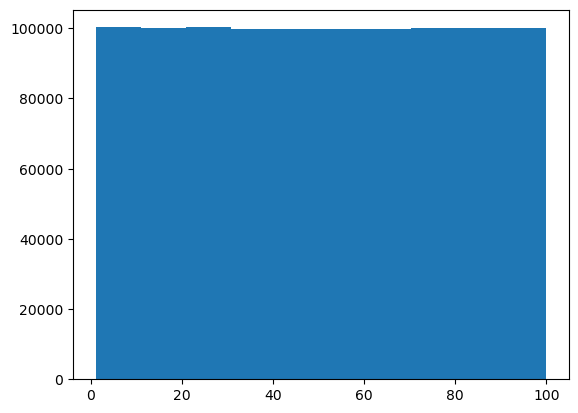

In [15]:
%matplotlib inline
plt.hist(data)

## Distribucion Normal

In [25]:
data = np.random.randn(1000000)

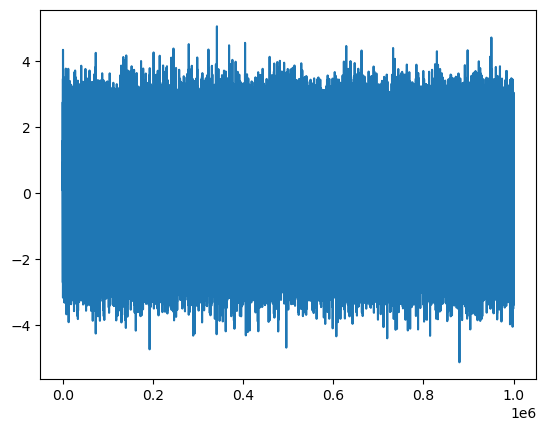

In [26]:
x = range(1,1000001)
plt.plot(x, data)

(array([2.30000e+01, 9.34000e+02, 1.76900e+04, 1.25316e+05, 3.39858e+05,
        3.52564e+05, 1.41099e+05, 2.12620e+04, 1.23000e+03, 2.40000e+01]),
 array([-5.14463728, -4.12389021, -3.10314314, -2.08239607, -1.06164901,
        -0.04090194,  0.97984513,  2.0005922 ,  3.02133927,  4.04208634,
         5.0628334 ]),
 <BarContainer object of 10 artists>)

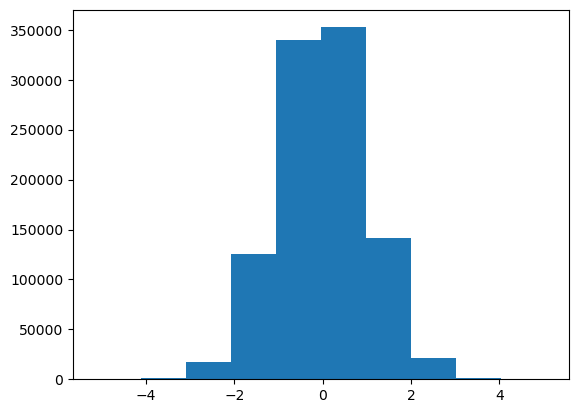

In [27]:
plt.hist(data)

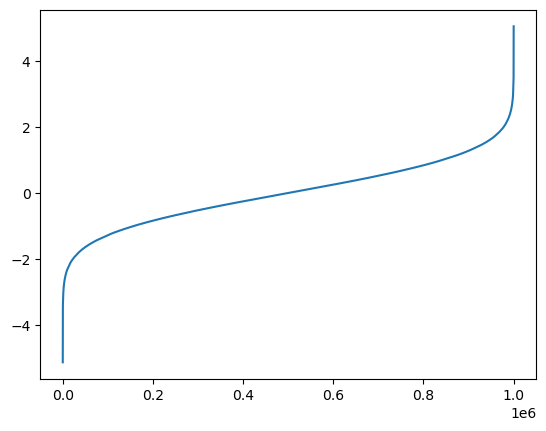

In [28]:
plt.plot(x,sorted(data))

(array([   7.,   60.,  380., 1425., 2618., 2917., 1831.,  607.,  135.,
          20.]),
 array([-4.53932284, -2.59855614, -0.65778944,  1.28297726,  3.22374396,
         5.16451066,  7.10527736,  9.04604406, 10.98681076, 12.92757746,
        14.86834416]),
 <BarContainer object of 10 artists>)

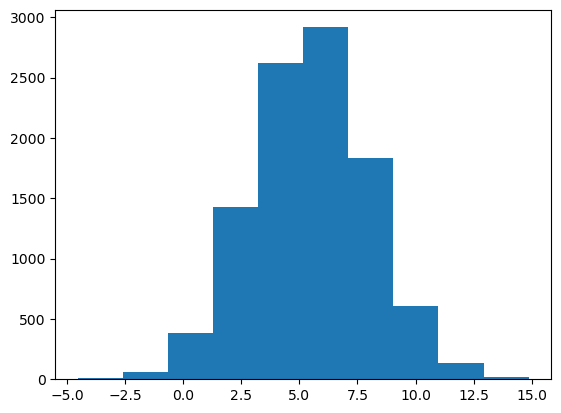

In [30]:
mu = 5.5
sd = 2.5
Z_10000 = np.random.randn(10000)
data = 5.5 + 2.5 * Z_10000 # Z = (X - mu) / sd -> N(0,1), X = mu + sd * Z
plt.hist(data)

In [31]:
data = np.random.randn(2,4)
data

array([[ 0.05697738,  0.71822101,  0.48430113,  0.84392178],
       [ 0.02880371, -0.33142701,  0.79702481, -0.35566789]])

## La simulacion de Monte Carlo

* Generamos dos numeros aleatorios uniforme x e y entre 0 y 1 en total 1000 veces
* Calcularemos x^2 + y^2
    * Si el valor es inferior a 1 -> Estamos dentro del circulo
    * Si el valor es  superior a 1 -> Estamos fuera del circulo
* Calculamos el numero total de veces que estan dentro del circulo y lo dividimos entre el numero total de intentos para
obtener una aproximacion de la probabilidad de caer dentro del circulo
* Usamos dicha probabilidad para aproximar el valor de pi
* Repetimos el experimento un numero suficiente de veces (por ejemplo 100) para obtener (100) diferentes aproximaciones de pi
* Calculamos el promedio de los 100 experimentos anteriores para dar un valor final de pi.

In [35]:
def pi_montecarlo(n, n_exp):
    pi_avg = 0
    pi_value_list = []
    for i in range(n_exp):
        value = 0
        x = np.random.uniform(0,1,n).tolist()
        y = np.random.uniform(0,1,n).tolist()
        for j in range(n):
            z = np.sqrt(x[j] * x[j] + y[j] * y[j])
            if z <= 1:
                value += 1
        float_value = float(value)
        pi_value = float_value * 4 / n
        pi_value_list.append(pi_value)
        pi_avg += pi_value
    
    pi = pi_avg / n_exp
    
    print(pi)
    fig = plt.plot(pi_value_list)
    return (pi, fig)

3.1442780000000017


(3.1442780000000017, [<matplotlib.lines.Line2D at 0x18f2d0ac8b0>])

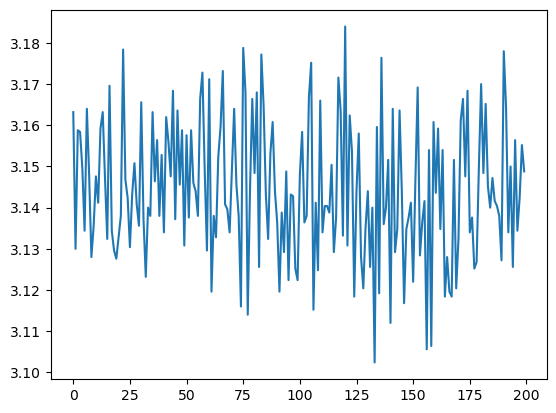

In [36]:
pi_montecarlo(10000, 200)

### Dummy Data Sets

In [42]:
n = 1000000
data = pd.DataFrame(
    {
        'A': np.random.randn(n),
        'B': 1.5 + 2.5 * np.random.randn(n),
        'C': np.random.uniform(5, 32, n)
    }
)

In [44]:
data.describe()

,A,B,C
count,1000000.000000,1000000.000000,1000000.000000
mean,-0.001239,1.501600,18.503507
std,0.999472,2.500333,7.793209
min,-5.397477,-11.016985,5.000033
25%,-0.674512,-0.185244,11.762289
50%,-0.001452,1.504752,18.492973
75%,0.672145,3.188756,25.261588
max,4.704367,13.723598,31.999998


(array([1.00000e+01, 3.43000e+02, 8.65800e+03, 7.84130e+04, 2.77475e+05,
        3.82355e+05, 2.05730e+05, 4.34570e+04, 3.44700e+03, 1.12000e+02]),
 array([-5.39747682, -4.38729244, -3.37710807, -2.36692369, -1.35673932,
        -0.34655494,  0.66362944,  1.67381381,  2.68399819,  3.69418256,
         4.70436694]),
 <BarContainer object of 10 artists>)

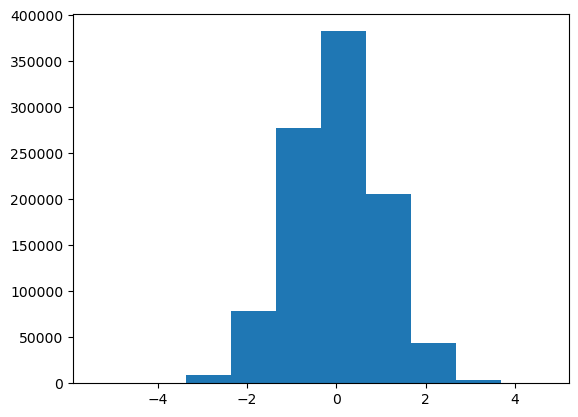

In [45]:
plt.hist(data["A"])

(array([3.50000e+01, 1.26900e+03, 1.95290e+04, 1.26227e+05, 3.29028e+05,
        3.47753e+05, 1.48919e+05, 2.53850e+04, 1.80300e+03, 5.20000e+01]),
 array([-11.0169846 ,  -8.54292634,  -6.06886809,  -3.59480984,
         -1.12075158,   1.35330667,   3.82736492,   6.30142318,
          8.77548143,  11.24953968,  13.72359794]),
 <BarContainer object of 10 artists>)

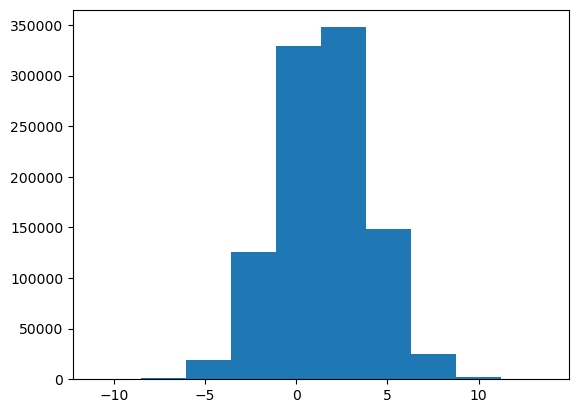

In [46]:
plt.hist(data["B"])

(array([ 99665.,  99779., 100614., 100053., 100161.,  99510.,  99892.,
         99829., 100495., 100002.]),
 array([ 5.00003257,  7.70002916, 10.40002575, 13.10002233, 15.80001892,
        18.50001551, 21.20001209, 23.90000868, 26.60000527, 29.30000186,
        31.99999844]),
 <BarContainer object of 10 artists>)

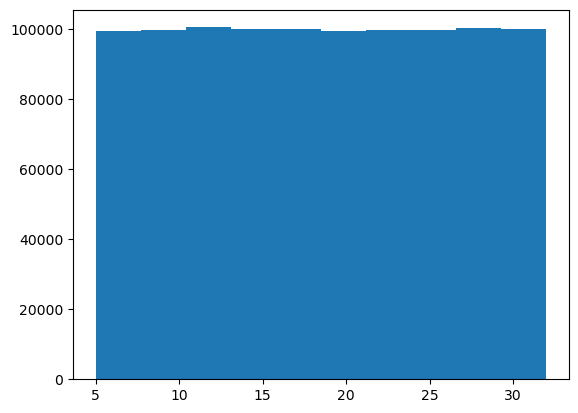

In [47]:
plt.hist(data["C"])

In [48]:
data = pd.read_csv("../datasets/customer-churn-model/Customer Churn Model.txt")

In [49]:
data.head()

,State,Account Length,Area Code,Phone,Int'l Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,...,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,Intl Mins,Intl Calls,Intl Charge,CustServ Calls,Churn?
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False.
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False.
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False.
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False.
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False.


In [51]:
column_names = data.columns.values.tolist()

In [52]:
a = len(column_names)
a

21

In [55]:
new_data = pd.DataFrame(
    {
        'Column Name': column_names,
        'A': np.random.randn(a),
        'B': np.random.uniform(0, 1, a)
    }, index = range(42, 42 + a)
)

In [56]:
new_data

,Column Name,A,B
42,State,0.282956,0.792124
43,Account Length,-1.509351,0.551860
44,Area Code,-0.230441,0.553434
45,Phone,1.135141,0.794914
46,Int'l Plan,1.617216,0.399717
47,VMail Plan,-0.679086,0.884233
48,VMail Message,2.019430,0.269005
49,Day Mins,-1.399809,0.615080
50,Day Calls,-1.339254,0.026414
51,Day Charge,-2.721858,0.187525
